# La arquitectura de una CNN: bloques, *pooling* y lo que la red supone

En `00-convoluciones/01_filtros_y_mapas_de_caracteristicas` vimos la pieza básica: un filtro de 3 × 3 que se desliza por la imagen y deja un mapa de características. Una convolución sola no clasifica nada. En el video *CNNs – Part 2: The Full Architecture* del curso, la red completa sigue una receta: [Conv → ReLU → MaxPool] × N → Flatten → Linear. La red del video tiene dos bloques, con 32 y 64 filtros, recibe imágenes de 28 × 28 y termina en `nn.Linear(64 * 7 * 7, 10)`.

Este notebook arma esa red pieza por pieza, la entrena con Fashion-MNIST y la pone frente a la red densa del módulo 2. Cada afirmación que viene de una fuente lleva su link, y la sección **Fuentes**, al final, reúne las citas textuales.

- Escribe la red del video y cuenta sus parámetros, capa por capa.
- Mira qué hace ReLU sobre un mapa de características.
- Programa el *max pooling* a mano, de dos maneras, y lo compara con `nn.MaxPool2d`. Después comprueba que en la pasada hacia atrás solo el máximo de cada ventana recibe gradiente.
- Deduce de dónde sale `64 * 7 * 7` y reproduce los errores que aparecen cuando la cuenta está mal.
- Entrena la red con el bucle completo del módulo 2 (validación en cada época, mejor época, prueba una sola vez) y muestra sus filtros y sus mapas.
- Mide cuánto ayuda el *pooling* cuando la imagen se mueve uno o más píxeles.
- Compara la CNN con la red densa: parámetros, multiplicaciones, tiempo y exactitud.
- Repite el experimento de los píxeles desordenados del módulo 2, ahora con la CNN.
- Calcula cuánto de la imagen ve una neurona de cada capa.

Usa Fashion-MNIST, que se guarda en `modulo-4/data` (si no está, `download=True` lo descarga). Tarda unos cinco minutos en una CPU, casi todo en entrenar la CNN dos veces.

**Contenido**

1. Preparación
2. La receta
3. ReLU sobre un mapa de características
4. *Max pooling* a mano
5. El gradiente del *pooling*
6. De dónde sale `64 * 7 * 7`
7. Entrenar la CNN
8. Qué aprendió: filtros y mapas de características
9. Desplazamientos chicos: lo que aporta el *pooling*
10. La CNN contra la red densa del módulo 2
11. Los píxeles desordenados, otra vez
12. Lo que ve cada neurona
13. Resumen y ejercicios

## 1. Preparación

Usamos [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) en vez de MNIST: fotos de ropa y calzado de Zalando, en gris y de 28 × 28, con 60.000 imágenes de entrenamiento, 10.000 de prueba y 10 clases. Sus autores lo proponen como reemplazo directo de MNIST (mismo tamaño, mismas divisiones) porque "MNIST is too easy": según su README, una red convolucional llega a 99.7% en MNIST. Con ropa queda más margen para ver diferencias entre modelos. Los nombres de las clases los traducimos.

In [1]:
import copy
import time

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"       # modulo-4/data

crudo_entrenamiento = datasets.FashionMNIST(root=RAIZ, train=True, download=True)
crudo_prueba = datasets.FashionMNIST(root=RAIZ, train=False, download=True)
NOMBRES = ["camiseta", "pantalón", "suéter", "vestido", "abrigo",
           "sandalia", "camisa", "zapatilla", "bolso", "botín"]
print("clases en torchvision:", crudo_entrenamiento.classes)
print("entrenamiento:", tuple(crudo_entrenamiento.data.shape), crudo_entrenamiento.data.dtype,
      "  prueba:", tuple(crudo_prueba.data.shape))


def miles(n):
    """12544 -> '12.544'."""
    return f"{n:,}".replace(",", ".")

Versión de PyTorch: 2.11.0+cpu
clases en torchvision: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
entrenamiento: (60000, 28, 28) torch.uint8   prueba: (10000, 28, 28)


Para que el notebook tarde unos minutos en una CPU no usamos las 60.000 imágenes de entrenamiento: tomamos al azar (con semilla) 15.000 para entrenar y otras 5.000, distintas, para validar. La prueba son las 10.000 imágenes del archivo de prueba, completas. La media y la desviación para normalizar salen solo de las 15.000 de entrenamiento.

Como todo cabe en memoria (las 30.000 imágenes, en `float32`, ocupan 30.000 × 784 × 4 bytes, unos 94 MB), las convertimos a tensores normalizados una sola vez, en vez de aplicar `ToTensor` y `Normalize` en cada época. `00-datos/01_transforms_dataset_y_dataloader` del módulo 2 mide cuánto se ahorra así. Guardamos también `FONDO`, el valor que toma un píxel negro después de normalizar: lo vamos a necesitar.

In [2]:
orden = torch.randperm(len(crudo_entrenamiento), generator=torch.Generator().manual_seed(0))
indices_entrenamiento, indices_validacion = orden[:15_000], orden[15_000:20_000]

pixeles = crudo_entrenamiento.data[indices_entrenamiento].float() / 255
MEDIA, DESVIACION = pixeles.mean().item(), pixeles.std().item()
del pixeles
FONDO = (0 - MEDIA) / DESVIACION          # el valor que toma un píxel negro después de normalizar


def preparar(imagenes):
    """De enteros [n, 28, 28] entre 0 y 255 a float32 normalizado [n, 1, 28, 28]."""
    return ((imagenes.float() / 255 - MEDIA) / DESVIACION).unsqueeze(1)


X_entrenamiento = preparar(crudo_entrenamiento.data[indices_entrenamiento])
y_entrenamiento = crudo_entrenamiento.targets[indices_entrenamiento]
X_validacion = preparar(crudo_entrenamiento.data[indices_validacion])
y_validacion = crudo_entrenamiento.targets[indices_validacion]
X_prueba = preparar(crudo_prueba.data)
y_prueba = crudo_prueba.targets

print(f"media {MEDIA:.4f}   desviación {DESVIACION:.4f}   fondo normalizado {FONDO:.3f}")
print("entrenamiento", tuple(X_entrenamiento.shape), "  validación", tuple(X_validacion.shape),
      "  prueba", tuple(X_prueba.shape))
print("imágenes por clase en el entrenamiento:", torch.bincount(y_entrenamiento).tolist())

media 0.2871   desviación 0.3538   fondo normalizado -0.811
entrenamiento (15000, 1, 28, 28)   validación (5000, 1, 28, 28)   prueba (10000, 1, 28, 28)
imágenes por clase en el entrenamiento: [1484, 1453, 1519, 1478, 1451, 1524, 1562, 1518, 1519, 1492]


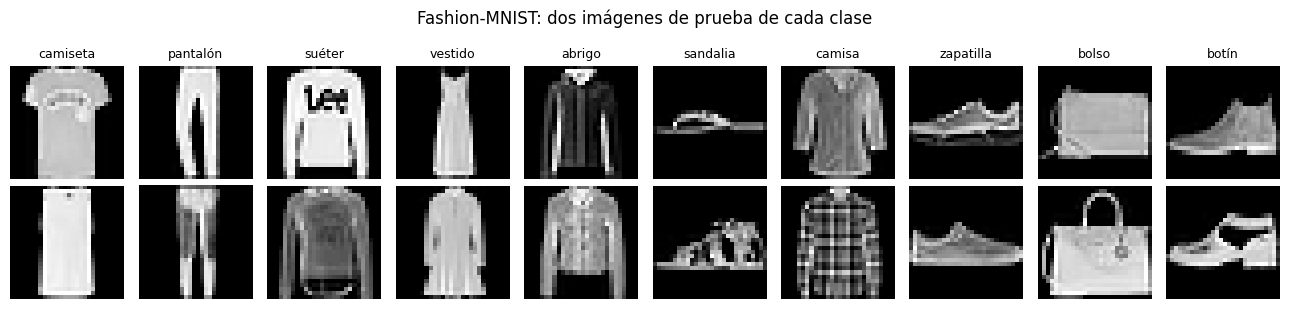

In [3]:
fig, ejes = plt.subplots(2, 10, figsize=(13, 3.2))
for clase in range(10):
    posiciones = torch.nonzero(y_prueba == clase).flatten()[:2]
    for fila, i in enumerate(posiciones):
        ejes[fila, clase].imshow(crudo_prueba.data[i], cmap="gray")
        ejes[fila, clase].axis("off")
    ejes[0, clase].set_title(NOMBRES[clase], fontsize=9)
plt.suptitle("Fashion-MNIST: dos imágenes de prueba de cada clase")
plt.tight_layout()
plt.show()

Las clases quedan equilibradas en el entrenamiento (entre 1.451 y 1.562 imágenes cada una). Hay grupos que se parecen: camiseta, suéter, abrigo y camisa son siluetas con mangas, y sandalia, zapatilla y botín son calzado visto de lado.

## 2. La receta

Los [apuntes de CS231n](https://cs231n.github.io/convolutional-networks/#layerpat) describen así el patrón más común de una red convolucional:

`INPUT -> [[CONV -> RELU]*N -> POOL?]*M -> [FC -> RELU]*K -> FC`

con N casi siempre entre 0 y 3 y K menor que 3. En palabras: unas pocas convoluciones con ReLU, un *pooling* que achica la imagen, y eso repetido hasta que la imagen queda pequeña. Al final van capas totalmente conectadas (*fully connected*, FC, lo que en PyTorch es `nn.Linear`), y la última da los puntajes de cada clase. El `?` después de POOL dice que el *pooling* es opcional.

La red del video es el caso N = 1, M = 2, K = 0: dos bloques [Conv → ReLU → Pool] y una sola capa lineal. Entre los bloques y la capa lineal va un paso que el patrón no escribe: aplanar. `nn.Linear` espera un vector por imagen, y después del segundo bloque cada imagen es un tensor de 64 × 7 × 7.

Las capas sin parámetros (`ReLU` y `MaxPool2d`) se pueden reusar: hay un solo `self.relu` y un solo `self.pool`, y cada uno se aplica dos veces.

In [4]:
class RedConvolucional(nn.Module):
    """Dos bloques [Conv -> ReLU -> MaxPool] y una capa lineal."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.lineal = nn.Linear(64 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))     # [n, 1, 28, 28]  -> [n, 32, 14, 14]
        x = self.pool(self.relu(self.conv2(x)))     # [n, 32, 14, 14] -> [n, 64, 7, 7]
        x = torch.flatten(x, start_dim=1)           # [n, 64, 7, 7]   -> [n, 3136]
        return self.lineal(x)                       # [n, 3136]       -> [n, 10]


torch.manual_seed(0)
red = RedConvolucional()
print(red)
print()
for nombre, parametro in red.named_parameters():
    print(f"{nombre:15s} {str(tuple(parametro.shape)):17s} {miles(parametro.numel()):>7s}")
total = sum(p.numel() for p in red.parameters())
print(f"{'total':33s} {miles(total):>7s}")
print(f"\nla capa lineal tiene el {sum(p.numel() for p in red.lineal.parameters()) / total:.0%} de los parámetros")

RedConvolucional(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (lineal): Linear(in_features=3136, out_features=10, bias=True)
)

conv1.weight    (32, 1, 3, 3)         288
conv1.bias      (32,)                  32
conv2.weight    (64, 32, 3, 3)     18.432
conv2.bias      (64,)                  64
lineal.weight   (10, 3136)         31.360
lineal.bias     (10,)                  10
total                              50.186

la capa lineal tiene el 63% de los parámetros


La red tiene 50.186 parámetros, la mitad que la red densa de `04-clasificacion-de-imagenes/01_mnist_de_punta_a_punta` del módulo 2 (101.770). Las cuentas:

- `conv1`: 32 filtros de 1 × 3 × 3 = 288 pesos, más 32 sesgos.
- `conv2`: 64 filtros de 32 × 3 × 3 = 18.432 pesos, más 64 sesgos. Cada filtro mira a la vez los 32 mapas que salen del primer bloque.
- `lineal`: 3136 × 10 = 31.360 pesos, más 10 sesgos.

La capa lineal tiene el 63% de los parámetros. Las convoluciones tienen pocos porque cada filtro es pequeño y se usa en todas las posiciones de la imagen. CS231n lo dice en la [introducción](https://cs231n.github.io/convolutional-networks/) de sus apuntes: la arquitectura supone que la entrada es una imagen, y eso permite "vastly reduce the amount of parameters in the network". En la sección 10 vemos el precio de ese ahorro.

## 3. ReLU sobre un mapa de características

Una convolución da números positivos y negativos. ReLU, según la [documentación de PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.ReLU.html), se aplica elemento por elemento y vale $\max(0, x)$: deja pasar lo positivo, pone en cero lo negativo y no cambia la forma del tensor.

Para verlo con un filtro que entendamos usamos uno hecho a mano, un detector de bordes verticales (el filtro de Sobel), sobre un botín del conjunto de prueba. El mapa es positivo donde la imagen pasa de oscuro a claro de izquierda a derecha, y negativo donde pasa de claro a oscuro.

Un detalle: rellenamos el borde con `FONDO` y no con ceros. Las imágenes están normalizadas, y en ellas el negro vale −0.811, no 0. Un relleno de ceros es un marco gris alrededor de la imagen, y el filtro ve ahí un borde que no existe. La última línea de la salida lo muestra en un píxel de fondo pegado al borde izquierdo.

valores del mapa: entre -8.53 y 5.90
ReLU deja en cero el 69.8% de los valores
   ya eran exactamente cero antes de ReLU (fondo plano): 51.9%
¿ReLU(z) - ReLU(-z) = z? True
fila 5, columna 0 (fondo): 0.00 con relleno de fondo, -3.25 con relleno de ceros


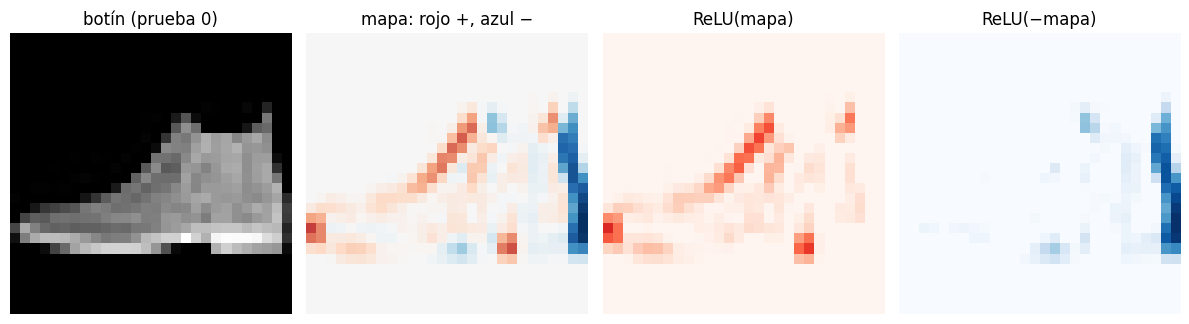

In [5]:
borde_vertical = torch.tensor([[-1.0, 0.0, 1.0],
                               [-2.0, 0.0, 2.0],
                               [-1.0, 0.0, 1.0]]).view(1, 1, 3, 3)    # Sobel: oscuro a la izquierda, claro a la derecha

i_botin = torch.nonzero(y_prueba == 9).flatten()[0].item()
x = X_prueba[i_botin : i_botin + 1]                                   # [1, 1, 28, 28]
mapa = F.conv2d(F.pad(x, (1, 1, 1, 1), value=FONDO), borde_vertical)  # relleno con el color del fondo
mapa_con_ceros = F.conv2d(x, borde_vertical, padding=1)               # relleno con ceros, como Conv2d(padding=1)
positivo = F.relu(mapa)
negativo = F.relu(-mapa)

print(f"valores del mapa: entre {mapa.min():.2f} y {mapa.max():.2f}")
print(f"ReLU deja en cero el {(positivo == 0).float().mean():.1%} de los valores")
print(f"   ya eran exactamente cero antes de ReLU (fondo plano): {(mapa == 0).float().mean():.1%}")
print("¿ReLU(z) - ReLU(-z) = z?", torch.allclose(positivo - negativo, mapa))
print(f"fila 5, columna 0 (fondo): {mapa[0, 0, 5, 0]:.2f} con relleno de fondo, "
      f"{mapa_con_ceros[0, 0, 5, 0]:.2f} con relleno de ceros")

limite = mapa.abs().max().item()
fig, ejes = plt.subplots(1, 4, figsize=(12, 3.4))
ejes[0].imshow(x[0, 0], cmap="gray")
ejes[0].set_title(f"{NOMBRES[9]} (prueba {i_botin})")
ejes[1].imshow(mapa[0, 0], cmap="RdBu_r", vmin=-limite, vmax=limite)
ejes[1].set_title("mapa: rojo +, azul −")
ejes[2].imshow(positivo[0, 0], cmap="Reds", vmin=0, vmax=limite)
ejes[2].set_title("ReLU(mapa)")
ejes[3].imshow(negativo[0, 0], cmap="Blues", vmin=0, vmax=limite)
ejes[3].set_title("ReLU(−mapa)")
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()

El mapa tiene los dos tipos de borde: rojo en el lado izquierdo de la caña y del empeine (de fondo negro a botín gris) y azul en el lado derecho (de botín a fondo). ReLU se queda solo con el rojo y deja en cero el 69.8% de los valores. La mayoría ya eran cero: el 51.9% del mapa es fondo plano, donde el filtro da exactamente 0. El resto son los bordes negativos, que ReLU borra.

Eso no quiere decir que una CNN no pueda ver los bordes de claro a oscuro. Como ReLU(z) − ReLU(−z) = z, la información está repartida entre un filtro y el mismo filtro con el signo cambiado: si la red necesita los dos tipos de borde, puede aprender los dos filtros.

¿Cuánto apaga ReLU en una red de verdad? Tomamos `conv1` de la red sin entrenar (la de la sección 2) y 500 imágenes de prueba. Calculamos también qué da cada filtro sobre fondo plano, que es una cuenta simple: `FONDO` × (suma de sus pesos) + sesgo.

In [6]:
with torch.no_grad():
    salida_conv1 = red.conv1(X_prueba[:500])                                   # [500, 32, 28, 28]
    en_fondo = FONDO * red.conv1.weight.sum(dim=(1, 2, 3)) + red.conv1.bias    # lo que da cada filtro sobre fondo plano
apagado = (salida_conv1 <= 0).float().mean(dim=(0, 2, 3))                      # fracción que ReLU deja en cero, por filtro

print(f"red sin entrenar, conv1 sobre 500 imágenes: ReLU deja en cero el {(salida_conv1 <= 0).float().mean():.1%}")
print(f"por filtro, entre {apagado.min():.0%} y {apagado.max():.0%}")
print(f"filtros que dan positivo sobre el fondo: {int((en_fondo > 0).sum())}, "
      f"apagan en promedio el {apagado[en_fondo > 0].mean():.0%}")
print(f"filtros que dan negativo sobre el fondo: {int((en_fondo <= 0).sum())}, "
      f"apagan en promedio el {apagado[en_fondo <= 0].mean():.0%}")

red sin entrenar, conv1 sobre 500 imágenes: ReLU deja en cero el 46.9%
por filtro, entre 8% y 89%
filtros que dan positivo sobre el fondo: 21, apagan en promedio el 37%
filtros que dan negativo sobre el fondo: 11, apagan en promedio el 66%


En la red sin entrenar, ReLU deja en cero el 46.9% de las salidas de `conv1`, casi la mitad. Pero no por igual: según el filtro, entre el 8% y el 89%. Buena parte de la diferencia la hace el fondo, que en estas imágenes es mucho (en el botín de arriba, la mitad del mapa). Los 21 filtros que dan un valor positivo sobre el fondo plano apagan en promedio el 37% de sus valores. Los 11 que dan negativo apagan el 66%, porque para ellos todo el fondo queda en cero de una vez.

Con pesos al azar, que un filtro apague el fondo o no depende del signo de la suma de sus pesos y de su sesgo: es cuestión de suerte. Al entrenar, la red ajusta esos pesos. En la sección 8 medimos cuánto apaga ReLU en la red entrenada.

## 4. *Max pooling* a mano

`nn.MaxPool2d(2)` parte cada mapa en ventanas de 2 × 2 que no se superponen y se queda con el máximo de cada una. Según la [documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html), el paso (`stride`) por defecto es igual al tamaño de la ventana, así que `MaxPool2d(2)` es ventana 2 y paso 2. No tiene parámetros: no aprende nada. Y trabaja canal por canal: entran 32 mapas y salen 32.

Con un ejemplo de 4 × 4:

In [7]:
ejemplo = torch.tensor([[1.0, 3.0, 2.0, 0.0],
                        [4.0, 2.0, 1.0, 5.0],
                        [0.0, 1.0, 7.0, 2.0],
                        [6.0, 2.0, 3.0, 4.0]]).view(1, 1, 4, 4)
print("entrada 4 × 4:\n", ejemplo[0, 0])
print("MaxPool2d(2):\n", nn.MaxPool2d(2)(ejemplo)[0, 0])

entrada 4 × 4:
 tensor([[1., 3., 2., 0.],
        [4., 2., 1., 5.],
        [0., 1., 7., 2.],
        [6., 2., 3., 4.]])
MaxPool2d(2):
 tensor([[4., 5.],
        [6., 7.]])


Cada número de la salida es el máximo de un cuadrante: 4 = máx(1, 3, 4, 2), 5 = máx(2, 0, 1, 5), 6 = máx(0, 1, 6, 2) y 7 = máx(7, 2, 3, 4).

Para programarlo hay que juntar los cuatro números de cada ventana en dimensiones propias y tomar el máximo ahí. Hay dos maneras sin bucles:

- **`reshape`.** Un eje de 28 se puede ver como 14 bloques de 2. Con `reshape(n, c, 14, 2, 14, 2)`, las dimensiones 3 y 5 recorren el interior de cada ventana, y `amax(dim=(3, 5))` toma el máximo sobre ellas.
- **`unfold(dim, tamaño, paso)`.** Corta una dimensión en ventanas de ese tamaño, avanzando ese paso, y agrega al final una dimensión nueva con el contenido de cada ventana. Aplicado al alto y al ancho da un tensor de `[n, c, 14, 14, 2, 2]`. Esta versión sirve también para ventanas que se superponen (paso menor que la ventana), cosa que la de `reshape` no puede hacer.

Las probamos con mapas reales: la salida de `conv1` después de ReLU, para las 500 imágenes.

In [8]:
def max_pool_con_reshape(x, k=2):
    """Max pooling de ventana k y paso k, partiendo cada eje en bloques de k."""
    n, c, alto, ancho = x.shape
    x = x[:, :, : alto // k * k, : ancho // k * k]            # lo que no completa una ventana se descarta
    bloques = x.reshape(n, c, alto // k, k, ancho // k, k)    # [n, c, fila de bloque, fila dentro, columna de bloque, columna dentro]
    return bloques.amax(dim=(3, 5))


def max_pool_con_unfold(x, k=2):
    """Lo mismo con unfold: cada ventana queda en las dos últimas dimensiones."""
    ventanas = x.unfold(2, k, k).unfold(3, k, k)              # [n, c, alto // k, ancho // k, k, k]
    return ventanas.amax(dim=(-2, -1))


mapas = F.relu(salida_conv1)                                  # [500, 32, 28, 28]
referencia = nn.MaxPool2d(2)(mapas)
print("forma:", tuple(mapas.shape), "->", tuple(referencia.shape))
print("¿reshape = MaxPool2d?", torch.equal(max_pool_con_reshape(mapas), referencia))
print("¿unfold  = MaxPool2d?", torch.equal(max_pool_con_unfold(mapas), referencia))
print(f"valores que quedan: {referencia.numel() / mapas.numel():.0%}")

forma:

(500, 32, 28, 28) -> (500, 32, 14, 14)


¿reshape = MaxPool2d? True


¿unfold  = MaxPool2d? True
valores que quedan: 25%


Las dos versiones dan exactamente lo mismo que `nn.MaxPool2d`: `torch.equal`, no solo `allclose`, porque tomar un máximo no redondea nada. Queda el 25% de los valores. CS231n lo dice así en su [sección de *pooling*](https://cs231n.github.io/convolutional-networks/#pool): la forma más común, ventanas de 2 × 2 con paso 2, termina "discarding 75% of the activations".

¿Y si el lado es impar? Después del segundo bloque el mapa es de 7 × 7, y un tercer *pooling* no tiene cómo partirlo en ventanas de 2.

In [9]:
impar = torch.arange(49.0).view(1, 1, 7, 7)
print("7 × 7 con MaxPool2d(2)                :", tuple(nn.MaxPool2d(2)(impar).shape))
print("7 × 7 con MaxPool2d(2, ceil_mode=True):", tuple(nn.MaxPool2d(2, ceil_mode=True)(impar).shape))
print("¿la última fila y columna influyen en la salida?",
      not torch.equal(nn.MaxPool2d(2)(impar), nn.MaxPool2d(2)(impar[:, :, :6, :6])))

7 × 7 con MaxPool2d(2)                : (1, 1, 3, 3)
7 × 7 con MaxPool2d(2, ceil_mode=True): (1, 1, 4, 4)
¿la última fila y columna influyen en la salida? False


Por defecto, la ventana que no cabe completa se descarta: 7 × 7 da 3 × 3, y la última fila y la última columna no influyen en nada (la salida es la misma si las borramos). Con `ceil_mode=True`, que según la documentación usa "ceil instead of floor to compute the output shape", la salida es de 4 × 4 y la última ventana queda incompleta. Es la fórmula de la sección *Shape* de la documentación, con *padding* 0 y *dilation* 1:

$$H_{out} = \left\lfloor \frac{H_{in} - \text{kernel\_size}}{\text{stride}} + 1 \right\rfloor = \left\lfloor \frac{7 - 2}{2} + 1 \right\rfloor = 3.$$

`05-profundizacion/01_aritmetica_de_la_convolucion` deduce esta fórmula y la comprueba con miles de combinaciones.

## 5. El gradiente del *pooling*

En la pasada hacia atrás, ¿qué gradiente recibe cada valor de la ventana? El máximo de cuatro números depende solo del mayor: si movemos un poco cualquiera de los otros tres, el máximo no cambia. Así que la derivada es 1 para el ganador y 0 para los demás. CS231n, en la [sección de *pooling*](https://cs231n.github.io/convolutional-networks/#pool), lo describe como "only routing the gradient to the input that had the highest value in the forward pass", y agrega que por eso la pasada hacia adelante suele guardar la posición del máximo (los *switches*). En PyTorch esas posiciones se piden con `return_indices=True`.

Lo comprobamos con los 32 mapas de una imagen. Sumamos todas las salidas del *pooling*, para que cada una reciba gradiente 1, y miramos qué llega a la entrada.

In [10]:
x = mapas[:1].clone().requires_grad_(True)                  # una imagen, 32 mapas de 28 × 28
salida, indices = F.max_pool2d(x, 2, return_indices=True)
salida.sum().backward()

gradiente = x.grad                                          # [1, 32, 28, 28]
por_ventana = gradiente.reshape(1, 32, 14, 2, 14, 2).sum(dim=(3, 5))      # suma del gradiente dentro de cada ventana
print("valores distintos del gradiente:", torch.unique(gradiente).tolist())
print(f"posiciones con gradiente 1: {miles(int((gradiente == 1).sum()))} de {miles(gradiente.numel())} "
      f"({(gradiente == 1).float().mean():.0%})")
print("¿cada ventana de 2 × 2 tiene exactamente un 1?", torch.equal(por_ventana, torch.ones_like(por_ventana)))

posiciones_gradiente = torch.nonzero(gradiente.flatten(2)[0] == 1)      # (canal, posición aplanada)
print("¿las posiciones con gradiente son los índices que guarda el pooling?",
      torch.equal(posiciones_gradiente[:, 1].view(32, -1).sort(dim=1).values,
                  indices[0].flatten(1).sort(dim=1).values))

valores distintos del gradiente: [0.0, 1.0]
posiciones con gradiente 1: 6.272 de 25.088 (25%)
¿cada ventana de 2 × 2 tiene exactamente un 1? True
¿las posiciones con gradiente son los índices que guarda el pooling? True


El gradiente toma solo dos valores, 0 y 1. Recibe 1 exactamente una posición de cada ventana de 2 × 2: 6.272 de 25.088, el 25%, una por cada salida del *pooling* (32 × 14 × 14 = 6.272). Y son justo las posiciones que guarda `return_indices=True`. El otro 75% recibe gradiente cero: esos valores no ganaron en su ventana, no llegaron a la salida y por eso no influyen en la pérdida.

Hay un caso que la regla no aclara: los empates. Después de ReLU, muchas ventanas tienen sus cuatro valores en cero. Igual hay un solo 1 por ventana (lo dice la tercera línea): PyTorch elige una de las posiciones empatadas y le pasa todo el gradiente. ¿Cuántas ventanas están así, y qué gradiente llega a la salida de `conv1`, antes de ReLU?

In [11]:
ventanas = x.detach().unfold(2, 2, 2).unfold(3, 2, 2).flatten(-2)       # [1, 32, 14, 14, 4]
todo_cero = (ventanas == 0).all(dim=-1)
print(f"ventanas de 2 × 2 con los cuatro valores en cero: {todo_cero.float().mean():.1%}")

z = salida_conv1[:1].clone().requires_grad_(True)           # antes de ReLU
F.max_pool2d(F.relu(z), 2).sum().backward()
print(f"gradiente que llega a la salida de conv1 (antes de ReLU): distinto de cero en "
      f"{(z.grad != 0).float().mean():.1%} de las posiciones")

ventanas de 2 × 2 con los cuatro valores en cero: 34.0%
gradiente que llega a la salida de conv1 (antes de ReLU): distinto de cero en 16.5% de las posiciones


El 34.0% de las ventanas tiene sus cuatro valores en cero: ReLU apagó toda esa zona. En esas ventanas el 1 cae en un valor que era cero, y al seguir hacia atrás ReLU lo corta, porque no deja pasar gradiente donde su entrada no era positiva. En las demás ventanas el máximo es positivo y el gradiente pasa.

Por eso, a la salida de `conv1`, el gradiente es distinto de cero solo en el 16.5% de las posiciones. La cuenta calza: el *pooling* deja pasar una posición de cada cuatro, y de esas se pierden las de las ventanas apagadas, 25% × (1 − 0.34) = 16.5%. En esta imagen, más de ocho de cada diez valores de `conv1` no reciben gradiente en este paso. Los pesos de `conv1` igual aprenden, porque cada filtro se usa en todas las posiciones y en todas las imágenes del lote, pero aprenden solo de las posiciones que ganaron.

## 6. De dónde sale `64 * 7 * 7`

La capa lineal necesita saber cuántos números recibe por imagen, y ese número depende de todo lo que pasa antes. La manera más segura de saberlo no es calcularlo de memoria, sino pasar un lote de prueba y mirar la forma después de cada capa. `torch.zeros` basta, porque la forma no depende de los valores.

In [12]:
x = torch.zeros(8, 1, 28, 28)
print(f"{'entrada':26s} {tuple(x.shape)}")
for nombre, capa in [("conv1", red.conv1), ("relu", red.relu), ("pool", red.pool),
                     ("conv2", red.conv2), ("relu", red.relu), ("pool", red.pool)]:
    x = capa(x)
    print(f"{nombre:6s} -> {str(tuple(x.shape)):18s} {miles(x[0].numel()):>6s} valores por imagen")
x = torch.flatten(x, start_dim=1)
print(f"{'flatten':26s} {tuple(x.shape)}")
print(f"{'lineal':26s} {tuple(red.lineal(x).shape)}")

entrada                    (8, 1, 28, 28)
conv1  -> (8, 32, 28, 28)    25.088 valores por imagen
relu   -> (8, 32, 28, 28)    25.088 valores por imagen
pool   -> (8, 32, 14, 14)     6.272 valores por imagen
conv2  -> (8, 64, 14, 14)    12.544 valores por imagen
relu   -> (8, 64, 14, 14)    12.544 valores por imagen
pool   -> (8, 64, 7, 7)       3.136 valores por imagen
flatten                    (8, 3136)
lineal                     (8, 10)


La cuenta, paso a paso:

- `conv1`, con kernel 3 y relleno 1, conserva el tamaño (28 × 28) y cambia los canales de 1 a 32.
- ReLU no cambia la forma.
- El *pooling* divide alto y ancho por 2: 28 → 14.
- `conv2` cambia los canales de 32 a 64 y conserva 14 × 14.
- El segundo *pooling*: 14 → 7.
- `torch.flatten(x, start_dim=1)` junta todo lo que hay desde la dimensión 1: 64 × 7 × 7 = 3136 números por imagen. La dimensión 0, la del lote, queda aparte.

Como dice el video, el 7 sale de los dos *pooling* (28 → 14 → 7) y el 64, del número de filtros de la última convolución. Las convoluciones no cuentan, porque con relleno 1 no cambian el tamaño.

Fíjate también en el número de valores por imagen. El primer bloque lo multiplica por 32 (de 784 a 25.088) y el *pooling* lo divide por 4; al final quedan 3136, cuatro veces la imagen original. La red cambia resolución por canales: menos posiciones, más rasgos por posición.

¿Qué pasa si la cuenta está mal? Tres errores típicos:

In [13]:
class SinUnPool(RedConvolucional):
    """Error 1: el que la escribió pensó que el segundo bloque no reducía, y puso 64 * 14 * 14."""

    def __init__(self):
        super().__init__()
        self.lineal = nn.Linear(64 * 14 * 14, 10)


class AplanaTodo(RedConvolucional):
    """Error 2: torch.flatten sin start_dim también aplana la dimensión del lote."""

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        return self.lineal(torch.flatten(x))


lote = X_prueba[:8]
for nombre, modelo, entrada in [("64 * 14 * 14 en la capa lineal", SinUnPool(), lote),
                                ("torch.flatten(x) sin start_dim", AplanaTodo(), lote),
                                ("imágenes de 32 × 32", RedConvolucional(), F.pad(lote, (2, 2, 2, 2), value=FONDO))]:
    try:
        modelo(entrada)
    except RuntimeError as error:
        print(f"{nombre:32s} RuntimeError: {error}")

with torch.no_grad():
    salida = AplanaTodo()(lote[:1])
print(f"\ncon un lote de una imagen, torch.flatten(x) sin start_dim no da error: la salida tiene forma {tuple(salida.shape)}")

64 * 14 * 14 en la capa lineal   RuntimeError: mat1 and mat2 shapes cannot be multiplied (8x3136 and 12544x10)


torch.flatten(x) sin start_dim   RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x25088 and 3136x10)


imágenes de 32 × 32              RuntimeError: mat1 and mat2 shapes cannot be multiplied (8x4096 and 3136x10)

con un lote de una imagen, torch.flatten(x) sin start_dim no da error: la salida tiene forma (10,)


Los tres terminan en el mismo mensaje, `mat1 and mat2 shapes cannot be multiplied`, y el mensaje dice qué pasó. `mat1` es la entrada de la capa lineal (imágenes × números por imagen) y `mat2` es su matriz de pesos traspuesta (entradas × salidas):

- **`64 * 14 * 14`.** La capa espera 12.544 números y le llegan 3136. Quien escribió la capa se olvidó de un *pooling*.
- **`torch.flatten(x)` sin `start_dim`.** `mat1` es de 1 × 25.088, y 25.088 = 8 × 3136. La [documentación de `torch.flatten`](https://docs.pytorch.org/docs/stable/generated/torch.flatten.html) muestra que por defecto `start_dim=0`: aplana también la dimensión del lote, y las 8 imágenes se vuelven un solo vector. En cambio `nn.Flatten` tiene `start_dim=1` por defecto ([documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.flatten.Flatten.html)), por eso en el módulo 2 no hacía falta decirlo. Son dos valores por defecto distintos para dos cosas con casi el mismo nombre.
- **Imágenes de 32 × 32.** La red solo funciona con el tamaño para el que se hizo la cuenta. Con 32 × 32 quedan 64 × 8 × 8 = 4096 números. Las convoluciones aceptan cualquier tamaño; la capa lineal, no.

El segundo error tiene una versión peor, la última línea: con un lote de una sola imagen no hay error, porque 1 × 3136 es justo lo que la capa espera, pero la salida pierde la dimensión del lote. El error aparecería recién con el primer lote de dos imágenes, o más adelante, en la función de pérdida.

`04-modular-e-inspeccion/01_bloques_inspeccion_y_depuracion` muestra cómo dejar que PyTorch haga la cuenta: con una función que hace la pasada de prueba antes de crear la capa lineal, o con `nn.LazyLinear`.

## 7. Entrenar la CNN

El bucle es el de `04-clasificacion-de-imagenes/01_mnist_de_punta_a_punta` del módulo 2: al bucle no le importa qué modelo entrena. Lo escribimos como dos funciones porque lo vamos a usar cuatro veces (la CNN, la red densa y las dos con los píxeles desordenados):

- `evaluar` calcula pérdida y exactitud en modo `eval()` y sin gradientes, de a 1000 imágenes.
- `entrenar` recorre las épocas con Adam (tasa 0.001, lotes de 64), valida al final de cada una, guarda una copia del estado de la mejor época y la carga al final. La copia es con `copy.deepcopy` porque `state_dict()` devuelve los mismos tensores que el optimizador sigue modificando.

In [14]:
def evaluar(modelo, X, y, lote=1000):
    """Pérdida y exactitud en (X, y), sin gradientes."""
    modelo.eval()
    criterio = nn.CrossEntropyLoss(reduction="sum")
    perdida, aciertos = 0.0, 0
    with torch.no_grad():
        for inicio in range(0, len(X), lote):
            salida = modelo(X[inicio : inicio + lote])
            perdida += criterio(salida, y[inicio : inicio + lote]).item()
            aciertos += (salida.argmax(dim=1) == y[inicio : inicio + lote]).sum().item()
    return perdida / len(X), aciertos / len(X)


def entrenar(modelo, X, y, X_val, y_val, epocas=3, lr=0.001, lote=64, informar=True):
    """Entrena con Adam, valida al final de cada época y deja cargado el estado de la mejor época."""
    cargador = DataLoader(TensorDataset(X, y), batch_size=lote, shuffle=True,
                          generator=torch.Generator().manual_seed(0))
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterio = nn.CrossEntropyLoss()
    historia = {"perdida": [], "exactitud": [], "perdida_val": [], "exactitud_val": [], "segundos": []}
    mejor = (-1.0, 0, None)

    for epoca in range(1, epocas + 1):
        inicio = time.perf_counter()
        modelo.train()
        perdida_total, aciertos = 0.0, 0
        for xb, yb in cargador:
            optimizador.zero_grad()
            salida = modelo(xb)
            perdida = criterio(salida, yb)
            perdida.backward()
            optimizador.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += (salida.argmax(dim=1) == yb).sum().item()
        segundos = time.perf_counter() - inicio
        perdida_val, exactitud_val = evaluar(modelo, X_val, y_val)

        for clave, valor in zip(historia, [perdida_total / len(X), aciertos / len(X), perdida_val, exactitud_val, segundos]):
            historia[clave].append(valor)
        if exactitud_val > mejor[0]:
            mejor = (exactitud_val, epoca, copy.deepcopy(modelo.state_dict()))
        if informar:
            print(f"época {epoca}   entrenamiento: pérdida {historia['perdida'][-1]:.3f}, exactitud {historia['exactitud'][-1]:.2%}   "
                  f"validación: pérdida {perdida_val:.3f}, exactitud {exactitud_val:.2%}   ({segundos:.0f} s)")

    modelo.load_state_dict(mejor[2])
    historia["mejor_epoca"] = mejor[1]
    return historia

Tres épocas sobre las 15.000 imágenes de entrenamiento:

In [15]:
EPOCAS = 3

torch.manual_seed(0)
cnn = RedConvolucional()
historia_cnn = entrenar(cnn, X_entrenamiento, y_entrenamiento, X_validacion, y_validacion, epocas=EPOCAS)
perdida_prueba_cnn, exactitud_prueba_cnn = evaluar(cnn, X_prueba, y_prueba)
print(f"\nmejor época: {historia_cnn['mejor_epoca']}   prueba (una sola vez): pérdida {perdida_prueba_cnn:.3f}, "
      f"exactitud {exactitud_prueba_cnn:.2%}")

época 1   entrenamiento: pérdida 0.595, exactitud 79.12%   validación: pérdida 0.435, exactitud 84.14%   (135 s)


época 2   entrenamiento: pérdida 0.391, exactitud 85.88%   validación: pérdida 0.368, exactitud 86.56%   (71 s)


época 3   entrenamiento: pérdida 0.330, exactitud 87.96%   validación: pérdida 0.338, exactitud 87.96%   (26 s)



mejor época: 3   prueba (una sola vez): pérdida 0.347, exactitud 87.22%


En tres épocas la CNN llega a 87.96% en validación y a 87.22% en prueba. La exactitud de validación subió en cada época (84.14%, 86.56% y 87.96%), así que la mejor época es la última: la red todavía estaba mejorando cuando paramos. Nos quedamos en tres épocas para que el notebook tarde pocos minutos.

No hay señales de sobreajuste: en la época 3 la exactitud de entrenamiento y la de validación son iguales (87.96%), y la pérdida de validación sigue bajando (0.435, 0.368, 0.338). En la época 1 la exactitud de entrenamiento (79.12%) es incluso menor que la de validación (84.14%). No es raro: la de entrenamiento es el promedio de los lotes de toda la época, cuando la red todavía estaba aprendiendo, y la de validación se mide al final, con la red ya mejor.

La prueba, medida una sola vez, da 0.74 puntos menos que la validación. Es una diferencia chica, como se espera si las 5.000 imágenes de validación representan bien a las 10.000 de prueba.

In [16]:
with torch.no_grad():
    predicciones = torch.cat([cnn(X_prueba[i : i + 1000]).argmax(dim=1) for i in range(0, len(X_prueba), 1000)])
print("exactitud de prueba por clase:")
for clase in range(10):
    de_la_clase = y_prueba == clase
    acierto = (predicciones[de_la_clase] == clase).float().mean().item()
    confusion = torch.bincount(predicciones[de_la_clase & (predicciones != clase)], minlength=10)
    print(f"   {NOMBRES[clase]:10s} {acierto:6.1%}   la confunde más con: {NOMBRES[int(confusion.argmax())]}")

exactitud de prueba por clase:
   camiseta    78.3%   la confunde más con: camisa
   pantalón    96.2%   la confunde más con: vestido
   suéter      75.9%   la confunde más con: camisa
   vestido     88.5%   la confunde más con: camisa
   abrigo      72.1%   la confunde más con: camisa
   sandalia    97.6%   la confunde más con: zapatilla
   camisa      76.8%   la confunde más con: camiseta
   zapatilla   95.0%   la confunde más con: botín
   bolso       96.8%   la confunde más con: camisa
   botín       95.0%   la confunde más con: zapatilla


Las clases fáciles son las que tienen una forma propia: sandalia (97.6%), bolso (96.8%), pantalón (96.2%), zapatilla y botín (95.0%). Las difíciles son las cuatro siluetas con mangas de la sección 1: abrigo (72.1%), suéter (75.9%), camisa (76.8%) y camiseta (78.3%).

La camisa está en el centro de la confusión. Es la clase con la que más se confunden la camiseta, el suéter, el vestido y el abrigo (y también el bolso), y la camisa, a su vez, se confunde sobre todo con la camiseta. Los errores del calzado, en cambio, quedan dentro del calzado: la sandalia se confunde con la zapatilla, la zapatilla con el botín y el botín con la zapatilla. Con 28 × 28 píxeles en gris, lo que separa una camisa de una camiseta o de un suéter son detalles chicos, como un cuello o una botonadura.

## 8. Qué aprendió: filtros y mapas de características

Los filtros de `conv1` son de 3 × 3 y miran directamente la imagen, así que se pueden dibujar.

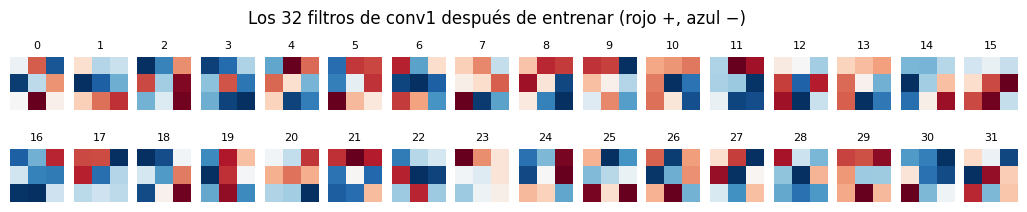

In [17]:
filtros = cnn.conv1.weight.detach()[:, 0]                  # [32, 3, 3]
fig, ejes = plt.subplots(2, 16, figsize=(13, 2.2))
for k, eje in enumerate(ejes.flat):
    limite = filtros[k].abs().max().item()
    eje.imshow(filtros[k], cmap="RdBu_r", vmin=-limite, vmax=limite)
    eje.set_title(str(k), fontsize=8)
    eje.axis("off")
plt.suptitle("Los 32 filtros de conv1 después de entrenar (rojo +, azul −)", y=1.04)
plt.show()

Con 3 × 3 píxeles no hay mucho que dibujar, y después de tres épocas los filtros no tienen la forma limpia de un Sobel. Aun así, en varios hay una parte positiva y otra negativa, el patrón de un detector de bordes como el de la sección 3: por ejemplo, en el 17 y en el 25 la fila de arriba y la de abajo tienen signos opuestos. No vale la pena interpretarlos uno por uno. Es más útil mirar qué hacen con una imagen: los mapas de características del botín, en las cuatro etapas de la red.

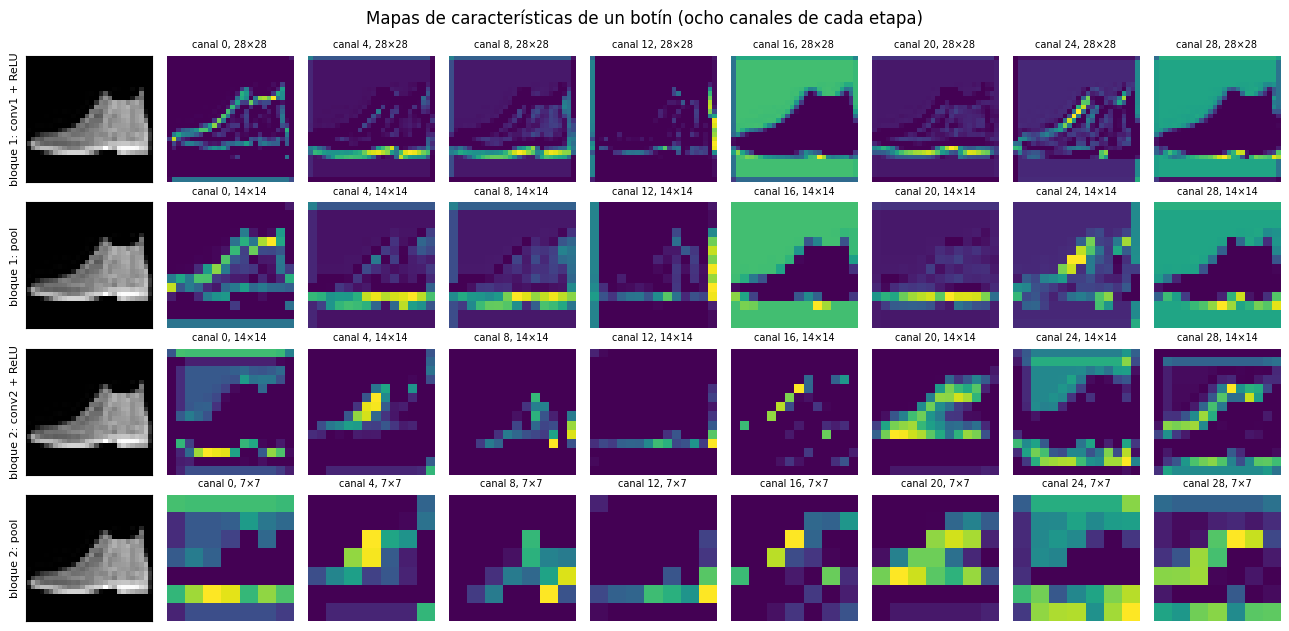

In [18]:
def activaciones(modelo, x):
    """Las salidas intermedias de la red para un lote x."""
    with torch.no_grad():
        a1 = modelo.relu(modelo.conv1(x))       # [n, 32, 28, 28]
        p1 = modelo.pool(a1)                    # [n, 32, 14, 14]
        a2 = modelo.relu(modelo.conv2(p1))      # [n, 64, 14, 14]
        p2 = modelo.pool(a2)                    # [n, 64, 7, 7]
    return {"bloque 1: conv1 + ReLU": a1, "bloque 1: pool": p1, "bloque 2: conv2 + ReLU": a2, "bloque 2: pool": p2}


salidas = activaciones(cnn, X_prueba[i_botin : i_botin + 1])
canales = [0, 4, 8, 12, 16, 20, 24, 28]
fig, ejes = plt.subplots(4, 9, figsize=(13, 6.4))
for fila, (nombre, a) in enumerate(salidas.items()):
    ejes[fila, 0].imshow(X_prueba[i_botin, 0], cmap="gray")
    ejes[fila, 0].set_ylabel(nombre, fontsize=8)
    ejes[fila, 0].set_xticks([])
    ejes[fila, 0].set_yticks([])
    for columna, canal in enumerate(canales, start=1):
        ejes[fila, columna].imshow(a[0, canal], cmap="viridis")
        ejes[fila, columna].set_title(f"canal {canal}, {a.shape[-1]}×{a.shape[-1]}", fontsize=7)
        ejes[fila, columna].axis("off")
plt.suptitle(f"Mapas de características de un {NOMBRES[9]} (ocho canales de cada etapa)")
plt.tight_layout()
plt.show()

In [19]:
salidas_lote = activaciones(cnn, X_prueba[:1000])
for nombre, a in salidas_lote.items():
    apagados = (a.amax(dim=(0, 2, 3)) == 0).sum().item()
    print(f"{nombre:24s} forma {str(tuple(a.shape[1:])):14s} valores en cero: {(a == 0).float().mean():5.1%}   "
          f"canales siempre en cero: {apagados}")

bloque 1: conv1 + ReLU   forma (32, 28, 28)   valores en cero: 45.0%   canales siempre en cero: 0
bloque 1: pool           forma (32, 14, 14)   valores en cero: 30.4%   canales siempre en cero: 0
bloque 2: conv2 + ReLU   forma (64, 14, 14)   valores en cero: 66.9%   canales siempre en cero: 0


bloque 2: pool           forma (64, 7, 7)     valores en cero: 44.4%   canales siempre en cero: 0


En el primer bloque los mapas todavía se leen como el botín, y cada canal resalta algo distinto:

- el canal 0, el contorno de arriba y la suela;
- los canales 4, 8 y 20, sobre todo la suela;
- el canal 12, el borde derecho;
- los canales 16 y 28 se encienden en el fondo y dejan el botín en cero, como los filtros de la sección 3 que daban positivo sobre el fondo.

Después del *pooling* son los mismos mapas, a la mitad de resolución. En el segundo bloque los mapas son más selectivos: el canal 4 de `conv2` se enciende casi solo en el borde inclinado de arriba, y el canal 12 casi en ninguna parte de esta imagen. A 7 × 7 ya no se reconoce el botín: cada valor resume una zona de 10 × 10 píxeles, como calculamos en la sección 12.

Los números, con 1000 imágenes de prueba:

- Después de `conv1` y ReLU, el 45.0% de los valores es cero, casi lo mismo que en la red sin entrenar (46.9% en la sección 3).
- En el segundo bloque ReLU apaga más: el 66.9%.
- El *pooling* baja la fracción de ceros, de 45.0% a 30.4% y de 66.9% a 44.4%, porque una salida del *pooling* es cero solo si los cuatro valores de su ventana lo son.
- Ningún canal está siempre en cero en estas 1000 imágenes: la red no tiene filtros muertos.

## 9. Desplazamientos chicos: lo que aporta el *pooling*

Según el video, el *max pooling* hace la red más robusta a pequeños cambios. La guía de Dumoulin y Visin, otra lectura del curso, va más lejos en su [capítulo 3](https://arxiv.org/abs/1603.07285): "pooling layers provide invariance to small translations of the input". ¿Cuánto?

La idea es esta. Si la imagen se mueve un píxel a la derecha, el mapa de una convolución también se mueve un píxel a la derecha, porque es el mismo filtro aplicado en todas partes. Comparado posición por posición con el original, eso es un cambio grande. Después de un *pooling* de 2 × 2, en cambio, un máximo que se movió un píxel puede seguir dentro de la misma ventana, y entonces esa salida no cambia.

Lo medimos con 1000 imágenes de prueba, movidas de 1 a 4 píxeles a la derecha (lo que entra por la izquierda es fondo). Para cada etapa de la red entrenada calculamos el cambio relativo, $\lVert \text{salida movida} - \text{salida original} \rVert \,/\, \lVert \text{salida original} \rVert$, donde 0 quiere decir que no cambió nada.

In [20]:
def desplazar(X, dx):
    """Mueve las imágenes dx píxeles a la derecha (o a la izquierda si dx < 0), rellenando con fondo."""
    p = abs(dx)
    ancha = F.pad(X, (p, p, 0, 0), value=FONDO)
    return ancha[:, :, :, p - dx : p - dx + X.shape[-1]]


muestra = X_prueba[:1000]
original = activaciones(cnn, muestra)
movidas = {dx: activaciones(cnn, desplazar(muestra, dx)) for dx in [1, 2, 3, 4]}

print(f"{'cambio relativo de la salida':26s}" + "".join(f"{f'mover {dx} px':>12s}" for dx in movidas))
for nombre in original:
    cambios = [((movidas[dx][nombre] - original[nombre]).norm() / original[nombre].norm()).item() for dx in movidas]
    print(f"{nombre:26s}" + "".join(f"{c:12.2f}" for c in cambios))

# Con 2 píxeles, ¿la salida del primer pooling es la original corrida una posición? (sin las columnas del borde)
movida_2 = movidas[2]["bloque 1: pool"][..., 3:12]
original_corrida = original["bloque 1: pool"][..., 2:11]
print(f"\nmover 2 px, pool 1 contra el original corrido una posición: cambio relativo "
      f"{((movida_2 - original_corrida).norm() / original_corrida.norm()).item():.4f}")

cambio relativo de la salida  mover 1 px  mover 2 px  mover 3 px  mover 4 px


bloque 1: conv1 + ReLU            0.54        0.72        0.78        0.82
bloque 1: pool                    0.44        0.65        0.74        0.78
bloque 2: conv2 + ReLU            0.63        0.96        1.09        1.12


bloque 2: pool                    0.47        0.66        0.82        0.94

mover 2 px, pool 1 contra el original corrido una posición: cambio relativo 0.0000


Comparadas posición por posición, las salidas cambian mucho con solo mover la imagen un píxel: un 54% después de `conv1` y ReLU. El *pooling* reduce el cambio, pero no lo elimina: 0.44 contra 0.54 en el primer bloque, y 0.47 contra 0.63 en el segundo. Con 4 píxeles, la salida del último *pooling* cambia 0.94, casi tanto como su propio tamaño. Después de `conv2` el cambio pasa de 1, es decir, la diferencia es más grande que la salida original. La invariancia que da el *pooling* es parcial, y la frase de Dumoulin y Visin hay que leerla así: invariancia a desplazamientos *pequeños*.

La última línea muestra lo que el *pooling* sí hace con exactitud. Con un desplazamiento de 2 píxeles, justo el paso de su ventana, la salida del primer *pooling* es la original corrida una posición, sin ningún otro cambio: 0.0000, sin contar las columnas del borde. El mapa se mueve junto con la imagen. Pero comparado posición por posición eso sigue contando como un cambio grande (0.65 en la tabla).

Que la salida final no dependa de dónde está el objeto lo tiene que conseguir la capa lineal, que es la única que mira todas las posiciones. La sección 10 mide cuánto lo consigue.

## 10. La CNN contra la red densa del módulo 2

La red densa es la de `04-clasificacion-de-imagenes/01_mnist_de_punta_a_punta` del módulo 2: `Flatten`, `Linear(784, 128)`, ReLU y `Linear(128, 10)`. La entrenamos con los mismos datos, la misma semilla, el mismo optimizador y las mismas épocas.

In [21]:
def red_densa():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))


torch.manual_seed(0)
densa = red_densa()
historia_densa = entrenar(densa, X_entrenamiento, y_entrenamiento, X_validacion, y_validacion, epocas=EPOCAS)
perdida_prueba_densa, exactitud_prueba_densa = evaluar(densa, X_prueba, y_prueba)
print(f"\nmejor época: {historia_densa['mejor_epoca']}   prueba (una sola vez): exactitud {exactitud_prueba_densa:.2%}")

época 1   entrenamiento: pérdida 0.613, exactitud 78.09%   validación: pérdida 0.479, exactitud 82.92%   (4 s)


época 2   entrenamiento: pérdida 0.451, exactitud 83.63%   validación: pérdida 0.448, exactitud 83.66%   (4 s)


época 3   entrenamiento: pérdida 0.394, exactitud 85.47%   validación: pérdida 0.403, exactitud 84.90%   (2 s)

mejor época: 3   prueba (una sola vez): exactitud 84.78%


Además de parámetros y exactitud contamos las multiplicaciones que hace cada red por imagen. En una convolución, cada valor de la salida cuesta `in_channels × 3 × 3` multiplicaciones; en una capa lineal, cada salida cuesta `in_features`. Para no hacer la cuenta a mano usamos un *forward hook*: una función que PyTorch llama cada vez que una capa termina su pasada hacia adelante, con la entrada y la salida de esa capa.

La tabla agrega la exactitud con las 10.000 imágenes de prueba movidas 1, 2 y 3 píxeles, y qué fracción de las predicciones cambia al mover un píxel.

In [22]:
def multiplicaciones_por_imagen(modelo):
    """Multiplicaciones de las capas Conv2d y Linear en la pasada hacia adelante de una imagen."""
    total = 0

    def contar(capa, entrada, salida):
        nonlocal total
        if isinstance(capa, nn.Conv2d):
            por_valor = capa.in_channels * capa.kernel_size[0] * capa.kernel_size[1]
        else:
            por_valor = capa.in_features
        total += salida[0].numel() * por_valor

    ganchos = [capa.register_forward_hook(contar) for capa in modelo.modules()
               if isinstance(capa, (nn.Conv2d, nn.Linear))]
    with torch.no_grad():
        modelo(X_prueba[:1])
    for gancho in ganchos:
        gancho.remove()
    return total


def predicciones_de(modelo, X):
    with torch.no_grad():
        return torch.cat([modelo(X[i : i + 1000]).argmax(dim=1) for i in range(0, len(X), 1000)])


filas = {}
for nombre, modelo, historia, exactitud in [("red densa (módulo 2)", densa, historia_densa, exactitud_prueba_densa),
                                            ("CNN de dos bloques", cnn, historia_cnn, exactitud_prueba_cnn)]:
    modelo.eval()
    base = predicciones_de(modelo, X_prueba)
    corridas = {dx: predicciones_de(modelo, desplazar(X_prueba, dx)) for dx in [1, 2, 3]}
    filas[nombre] = {
        "parametros": sum(p.numel() for p in modelo.parameters()),
        "multiplicaciones": multiplicaciones_por_imagen(modelo),
        "segundos": sum(historia["segundos"]) / EPOCAS,
        "prueba": exactitud,
        "movidas": [(corridas[dx] == y_prueba).float().mean().item() for dx in [1, 2, 3]],
        "cambian": (corridas[1] != base).float().mean().item(),
    }

print(f"{'':22s}{'parámetros':>11s}{'mult./imagen':>14s}{'s/época':>9s}{'prueba':>9s}"
      f"{'mover 1':>9s}{'mover 2':>9s}{'mover 3':>9s}{'cambian con 1 px':>18s}")
for nombre, f in filas.items():
    print(f"{nombre:22s}{miles(f['parametros']):>11s}{miles(f['multiplicaciones']):>14s}{f['segundos']:9.1f}"
          f"{f['prueba']:9.2%}" + "".join(f"{m:9.2%}" for m in f["movidas"]) + f"{f['cambian']:18.2%}")

d, c = filas["red densa (módulo 2)"], filas["CNN de dos bloques"]
print(f"\nla CNN hace {c['multiplicaciones'] / d['multiplicaciones']:.0f} veces más multiplicaciones por imagen; "
      f"en esta ejecución tardó {c['segundos'] / d['segundos']:.0f} veces más por época")

                       parámetros  mult./imagen  s/época   prueba  mover 1  mover 2  mover 3  cambian con 1 px
red densa (módulo 2)      101.770       101.632      3.2   84.78%   76.86%   56.88%   37.02%            15.95%
CNN de dos bloques         50.186     3.869.824     77.4   87.22%   84.90%   76.42%   51.29%             8.04%

la CNN hace 38 veces más multiplicaciones por imagen; en esta ejecución tardó 24 veces más por época


La CNN tiene la mitad de parámetros que la red densa y es más exacta: 87.22% contra 84.78% en prueba, 2.44 puntos más. Pero hace 38 veces más multiplicaciones por imagen (3.869.824 contra 101.632), porque cada filtro, aunque tenga solo 9 o 288 pesos, se aplica en todas las posiciones de la imagen. Es el precio del ahorro de parámetros de la sección 2. En esta ejecución cada época de la CNN tardó 24 veces más que la de la red densa; la razón exacta depende de la CPU y de cuánta carga tenga.

Con las imágenes movidas, la CNN aguanta mejor:

- Con un píxel, la CNN pierde 2.32 puntos (de 87.22% a 84.90%) y la red densa 7.92 (de 84.78% a 76.86%).
- Con tres píxeles, la CNN queda en 51.29% y la red densa en 37.02%.
- Al mover un píxel, la CNN cambia su predicción en el 8.04% de las imágenes y la red densa en el 15.95%, el doble.

Pero ninguna de las dos es invariante: con tres píxeles, las dos pierden mucho. Las dos se entrenaron con imágenes centradas, como vienen en Fashion-MNIST, y nunca vieron una movida. Para enseñarle a una red esos desplazamientos está el aumento de datos de `modulo-3/03-robustez/01_pipelines_a_prueba_de_fallas`.

## 11. Los píxeles desordenados, otra vez

En `04-clasificacion-de-imagenes/02_experimentos_con_mnist` del módulo 2 desordenamos los píxeles de MNIST con una permutación fija, la misma para todas las imágenes, y la red densa aprendió igual de bien. Para una capa lineal el orden de las entradas no significa nada: cambiarlo es reordenar las columnas de la primera matriz de pesos. Ese notebook terminaba diciendo que las CNN parten del supuesto contrario, que los píxeles vecinos están relacionados.

Ahora lo podemos medir. Usamos la misma permutación (semilla 0) sobre Fashion-MNIST y entrenamos las dos redes desde cero, con las mismas semillas y épocas que antes.

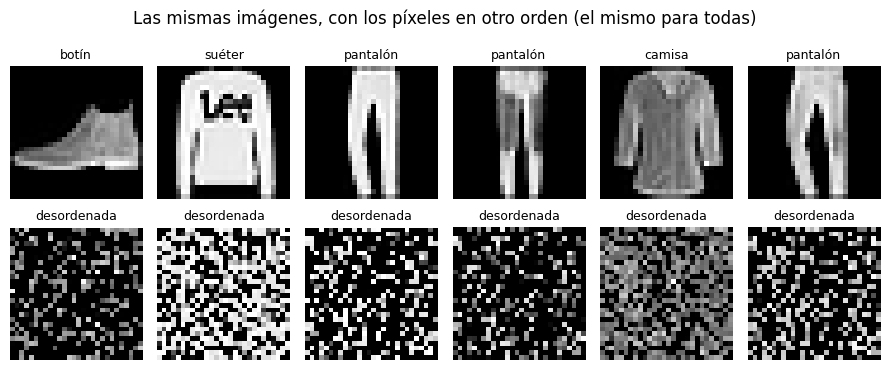

In [23]:
permutacion = torch.randperm(784, generator=torch.Generator().manual_seed(0))


def permutar(X):
    return X.flatten(1)[:, permutacion].reshape(-1, 1, 28, 28)


X_entrenamiento_p, X_validacion_p, X_prueba_p = permutar(X_entrenamiento), permutar(X_validacion), permutar(X_prueba)

fig, ejes = plt.subplots(2, 6, figsize=(9, 3.9))
for k in range(6):
    ejes[0, k].imshow(X_prueba[k, 0], cmap="gray")
    ejes[1, k].imshow(X_prueba_p[k, 0], cmap="gray")
    ejes[0, k].set_title(NOMBRES[y_prueba[k]], fontsize=9)
    ejes[1, k].set_title("desordenada", fontsize=9)
for eje in ejes.flat:
    eje.axis("off")
plt.suptitle("Las mismas imágenes, con los píxeles en otro orden (el mismo para todas)")
plt.tight_layout()
plt.show()

In [24]:
torch.manual_seed(0)
densa_p = red_densa()
historia_densa_p = entrenar(densa_p, X_entrenamiento_p, y_entrenamiento, X_validacion_p, y_validacion,
                            epocas=EPOCAS, informar=False)
torch.manual_seed(0)
cnn_p = RedConvolucional()
historia_cnn_p = entrenar(cnn_p, X_entrenamiento_p, y_entrenamiento, X_validacion_p, y_validacion,
                          epocas=EPOCAS, informar=False)

resultados = {
    "red densa": (exactitud_prueba_densa, evaluar(densa_p, X_prueba_p, y_prueba)[1]),
    "CNN": (exactitud_prueba_cnn, evaluar(cnn_p, X_prueba_p, y_prueba)[1]),
}
print(f"{'prueba':10s}{'originales':>12s}{'desordenadas':>14s}{'diferencia':>12s}")
for nombre, (con_orden, desordenada) in resultados.items():
    print(f"{nombre:10s}{con_orden:12.2%}{desordenada:14.2%}{100 * (desordenada - con_orden):+11.2f} pts")
print(f"\nexactitud de entrenamiento en la última época:")
print(f"   red densa: originales {historia_densa['exactitud'][-1]:.2%}, desordenadas {historia_densa_p['exactitud'][-1]:.2%}")
print(f"   CNN:       originales {historia_cnn['exactitud'][-1]:.2%}, desordenadas {historia_cnn_p['exactitud'][-1]:.2%}")

prueba      originales  desordenadas  diferencia
red densa       84.78%        84.20%      -0.58 pts
CNN             87.22%        83.74%      -3.48 pts

exactitud de entrenamiento en la última época:
   red densa: originales 85.47%, desordenadas 85.33%
   CNN:       originales 87.96%, desordenadas 85.89%


Como en el módulo 2, a la red densa casi no le importa el desorden: pierde 0.58 puntos. No da exactamente lo mismo porque los pesos iniciales no se reordenan junto con los píxeles, y el entrenamiento sigue otro camino.

A la CNN el desorden le cuesta 3.48 puntos, y queda en 83.74%, por debajo de la red densa con píxeles desordenados (84.20%). En la imagen desordenada, los vecinos de un píxel son píxeles de cualquier parte de la imagen, y el supuesto de la CNN deja de cumplirse: que lo útil está en los vecindarios y que el mismo filtro sirve en todas partes. La exactitud de entrenamiento muestra lo mismo: la CNN baja de 87.96% a 85.89%, mientras la red densa casi no cambia (85.47% contra 85.33%). No es sobreajuste: con los píxeles desordenados, la CNN aprende peor también en el entrenamiento.

Lo que llama la atención es que la CNN no se derrumba: 83.74% está lejos del 10% del azar. Cada filtro pasa a combinar nueve píxeles cualesquiera, y la capa lineal del final, con el 63% de los parámetros, sigue mirando todas las posiciones. La red aprende igual, pero pierde la ventaja que le daba su supuesto.

## 12. Lo que ve cada neurona

Una neurona de `conv1` mira 3 × 3 píxeles. Ese es su campo receptivo (*receptive field*), que CS231n, para una sola capa, iguala al tamaño del filtro. Las capas siguientes ven más, porque cada neurona mira varias neuronas de la capa anterior.

La cuenta lleva dos números por capa: el campo (cuántos píxeles de la imagen ve una neurona, por lado) y el salto (cuántos píxeles de la imagen separan a dos neuronas vecinas). Una capa con ventana $k$ y paso $s$ le suma $(k - 1) \times \text{salto}$ al campo y multiplica el salto por $s$.

In [25]:
capas = [("conv1", 3, 1), ("pool 1", 2, 2), ("conv2", 3, 1), ("pool 2", 2, 2)]      # (nombre, ventana, paso)
campo, salto = 1, 1
calculado = {}
for nombre, ventana, paso in capas:
    campo += (ventana - 1) * salto        # la ventana nueva abarca (ventana - 1) saltos más que una neurona de la capa anterior
    salto *= paso                         # cuántos píxeles de la entrada separan a dos neuronas vecinas
    calculado[nombre] = (campo, salto)
    print(f"{nombre:7s} campo {campo:2d} × {campo:<2d}   salto {salto} px")

conv1   campo  3 × 3    salto 1 px
pool 1  campo  4 × 4    salto 2 px
conv2   campo  8 × 8    salto 2 px
pool 2  campo 10 × 10   salto 4 px


Las convoluciones agrandan el campo y el *pooling* agranda el salto, y así hace que la convolución siguiente agrande el campo más rápido: `conv1` suma 2 píxeles y `conv2` suma 4, porque sus vecinas están a 2 píxeles de distancia en la imagen. CS231n hace la misma cuenta para tres convoluciones de 3 × 3 seguidas, sin *pooling*: 3, después "a 5x5 view of the input volume" y después "a 7x7 view".

Lo comprobamos con una copia geométrica de la red: un solo canal, todos los pesos en 1, sin ReLU y con *pooling* promedio en vez de máximo, para que ninguna posición de la ventana quede sin gradiente. El gradiente de una neurona central respecto de la imagen es distinto de cero justo en la región que esa neurona ve.

conv1   neurona (14, 14) de un mapa de 28 × 28: región de 3 × 3 píxeles   ¿coincide con la cuenta? True
pool 1  neurona (7, 7) de un mapa de 14 × 14: región de 4 × 4 píxeles   ¿coincide con la cuenta? True
conv2   neurona (7, 7) de un mapa de 14 × 14: región de 8 × 8 píxeles   ¿coincide con la cuenta? True
pool 2  neurona (3, 3) de un mapa de 7 × 7: región de 10 × 10 píxeles   ¿coincide con la cuenta? True


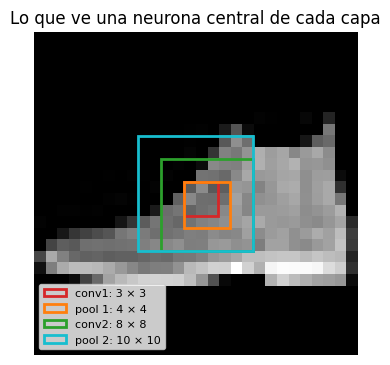

In [26]:
geometrica = nn.Sequential(nn.Conv2d(1, 1, 3, padding=1, bias=False), nn.AvgPool2d(2),
                           nn.Conv2d(1, 1, 3, padding=1, bias=False), nn.AvgPool2d(2))
with torch.no_grad():
    geometrica[0].weight.fill_(1.0)
    geometrica[2].weight.fill_(1.0)

regiones = {}
for k, (nombre, _, _) in enumerate(capas, start=1):
    entrada = torch.ones(1, 1, 28, 28, requires_grad=True)
    salida = geometrica[:k](entrada)
    centro = salida.shape[-1] // 2
    salida[0, 0, centro, centro].backward()
    filas_region, columnas_region = torch.nonzero(entrada.grad[0, 0], as_tuple=True)
    regiones[nombre] = (filas_region.min().item(), filas_region.max().item(),
                        columnas_region.min().item(), columnas_region.max().item())
    alto = filas_region.max().item() - filas_region.min().item() + 1
    ancho = columnas_region.max().item() - columnas_region.min().item() + 1
    print(f"{nombre:7s} neurona ({centro}, {centro}) de un mapa de {salida.shape[-1]} × {salida.shape[-1]}: "
          f"región de {alto} × {ancho} píxeles   ¿coincide con la cuenta? {alto == ancho == calculado[nombre][0]}")

fig, eje = plt.subplots(figsize=(4.2, 4.2))
eje.imshow(X_prueba[i_botin, 0], cmap="gray")
for (nombre, (f0, f1, c0, c1)), color in zip(regiones.items(), ["tab:red", "tab:orange", "tab:green", "tab:cyan"]):
    eje.add_patch(Rectangle((c0 - 0.5, f0 - 0.5), c1 - c0 + 1, f1 - f0 + 1, fill=False, edgecolor=color,
                            linewidth=2, label=f"{nombre}: {f1 - f0 + 1} × {c1 - c0 + 1}"))
eje.legend(fontsize=8, loc="lower left")
eje.set_title("Lo que ve una neurona central de cada capa")
eje.axis("off")
plt.show()

Una neurona del último *pooling* ve 10 × 10 píxeles, alrededor de un octavo de la imagen. Ninguna neurona convolucional ve el botín entero: la que junta las 7 × 7 posiciones es la capa lineal. Las regiones no están centradas en el mismo punto porque una ventana de 2 × 2 no tiene un píxel central.

`05-profundizacion/02_campos_receptivos` sigue este tema en detalle: la fórmula cerrada, qué cambian ReLU y el *max pooling*, y el campo receptivo efectivo.

## 13. Resumen

- La receta de una CNN es [Conv → ReLU → MaxPool] × N → Flatten → Linear; CS231n la escribe de forma más general. La red del video, con dos bloques de 32 y 64 filtros, tiene 50.186 parámetros, y el 63% está en la capa lineal.
- ReLU deja en cero lo negativo sin cambiar la forma. Cuánto apaga depende del filtro: en la red sin entrenar, entre el 8% y el 89% de los valores de `conv1`. Lo que borra no se pierde si la red aprende también el filtro con el signo contrario.
- `MaxPool2d(2)` se programa en una línea con `reshape` o con `unfold`, y da exactamente lo mismo que PyTorch. Conserva el 25% de los valores, y con un lado impar descarta la última fila y la última columna, salvo con `ceil_mode=True`.
- Hacia atrás, el *pooling* manda todo el gradiente al máximo de cada ventana. Junto con ReLU, en nuestra imagen solo el 16.5% de la salida de `conv1` recibió gradiente.
- `64 * 7 * 7` sale de los dos *pooling* (28 → 14 → 7) y de los 64 filtros de la última convolución, y lo más seguro es comprobarlo con una pasada de prueba. Si la cuenta está mal, el error es `mat1 and mat2 shapes cannot be multiplied`. `torch.flatten` sin `start_dim` aplana también el lote, y con un lote de una imagen no da error.
- En tres épocas, la CNN llegó a 87.22% en prueba, contra 84.78% de la red densa, con la mitad de los parámetros pero 38 veces más multiplicaciones por imagen. Las clases más difíciles son las siluetas con mangas, que se confunden sobre todo con la camisa.
- El *pooling* da una invariancia parcial a los desplazamientos. Al mover la imagen un píxel, la CNN cambia su predicción en el 8.04% de las imágenes y la red densa en el 15.95%; con tres píxeles, las dos pierden mucho.
- Con los píxeles desordenados, la red densa pierde 0.58 puntos y la CNN 3.48: la CNN depende de que los píxeles vecinos estén relacionados.
- Una neurona del último *pooling* ve 10 × 10 píxeles. Las convoluciones agrandan el campo receptivo y el *pooling* agranda el salto.

## Ejercicios

1. **Un tercer bloque.** Agrega `Conv2d(64, 128, 3, padding=1)`, ReLU y `MaxPool2d(2)`. Antes de ejecutar, calcula el número que va en la capa lineal (ojo: 7 es impar). Compruébalo con la pasada de prueba de la sección 6 y repite la cuenta con `ceil_mode=True`.
2. ***Pooling* promedio a mano.** Escribe `avg_pool_con_unfold` igual que la versión de la sección 4, pero con `mean`, y compárala con `nn.AvgPool2d(2)` usando `torch.allclose` (¿por qué no `torch.equal`?). Después repite la sección 5: ¿cuánto gradiente recibe cada posición de una ventana?
3. **Sin *pooling*.** CS231n menciona redes que reemplazan el *pooling* por convoluciones con paso 2. Cambia cada `MaxPool2d(2)` por `Conv2d(c, c, 3, stride=2, padding=1)` y compara parámetros, multiplicaciones, exactitud y la tabla de desplazamientos de la sección 9.
4. **Desplazamientos verticales y en diagonal.** La función `desplazar` solo mueve en horizontal. Escribe la versión vertical y repite la tabla de la sección 9. Después combina las dos para mover 1 píxel en diagonal. ¿El *pooling* ayuda igual?
5. **Un desorden más suave.** En la sección 11 la permutación mezcla todos los píxeles. Prueba una que solo cambie el orden de las 28 filas (la misma para todas las imágenes) y entrena las dos redes. ¿Qué parte del supuesto de la CNN se rompe y qué parte no?
6. **Filtros de 5 × 5.** Calcula, con la cuenta de la sección 12, el campo receptivo de cada capa si las dos convoluciones usan `kernel_size=5, padding=2`. Compruébalo con la copia geométrica.
7. **El canal que más importa.** Pon en cero un canal de `conv2` a la vez (sus pesos y su sesgo, dentro de `torch.no_grad()` y sobre una copia de la red) y mide la exactitud de validación. ¿Hay canales sin los que la red casi no cambia? ¿Son los que más seguido están en cero? Mídelo con `activaciones`.

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- **Video *CNNs – Part 2: The Full Architecture*** del curso: la receta [Conv → ReLU → MaxPool] × N → Flatten → Linear, la red de dos bloques con 32 y 64 filtros sobre imágenes de 28 × 28 y `nn.Linear(64 * 7 * 7, 10)`, la cuenta 28 → 14 → 7, y la afirmación de que el *max pooling* conserva la información más importante y hace la red más eficiente y más robusta a pequeños cambios.
- **CS231n**, [*Convolutional Neural Networks: Architectures, Convolution / Pooling Layers*](https://cs231n.github.io/convolutional-networks/) (Stanford):
  - [Introducción](https://cs231n.github.io/convolutional-networks/): "ConvNet architectures make the explicit assumption that the inputs are images, which allows us to encode certain properties into the architecture. These then make the forward function more efficient to implement and vastly reduce the amount of parameters in the network."
  - [*Architecture Overview*](https://cs231n.github.io/convolutional-networks/#overview): "Regular Neural Nets don’t scale well to full images"; "Clearly, this full connectivity is wasteful and the huge number of parameters would quickly lead to overfitting."
  - [*Convolutional Layer*](https://cs231n.github.io/convolutional-networks/#conv), *Local Connectivity*: "we will connect each neuron to only a local region of the input volume. The spatial extent of this connectivity is a hyperparameter called the receptive field of the neuron (equivalently this is the filter size)." *Parameter Sharing*: "we can dramatically reduce the number of parameters by making one reasonable assumption: That if one feature is useful to compute at some spatial position (x,y), then it should also be useful to compute at a different position (x2,y2)"; "If detecting a horizontal edge is important at some location in the image, it should intuitively be useful at some other location as well due to the translationally-invariant structure of images"; "Note that sometimes the parameter sharing assumption may not make sense. This is especially the case when the input images to a ConvNet have some specific centered structure".
  - [*Pooling Layer*](https://cs231n.github.io/convolutional-networks/#pool): "Its function is to progressively reduce the spatial size of the representation to reduce the amount of parameters and computation in the network, and hence to also control overfitting"; "The most common form is a pooling layer with filters of size 2x2 applied with a stride of 2 downsamples every depth slice in the input by 2 along both width and height, discarding 75% of the activations. Every MAX operation would in this case be taking a max over 4 numbers (little 2x2 region in some depth slice). The depth dimension remains unchanged." En *Backpropagation*: "the backward pass for a max(x, y) operation has a simple interpretation as only routing the gradient to the input that had the highest value in the forward pass. Hence, during the forward pass of a pooling layer it is common to keep track of the index of the max activation (sometimes also called the switches) so that gradient routing is efficient during backpropagation." En *Getting rid of pooling*: "Many people dislike the pooling operation and think that we can get away without it"; "To reduce the size of the representation they suggest using larger stride in CONV layer once in a while."
  - [*Layer Patterns*](https://cs231n.github.io/convolutional-networks/#layerpat): "The most common form of a ConvNet architecture stacks a few CONV-RELU layers, follows them with POOL layers, and repeats this pattern until the image has been merged spatially to a small size. At some point, it is common to transition to fully-connected layers. The last fully-connected layer holds the output, such as the class scores"; el patrón "INPUT -> [[CONV -> RELU]*N -> POOL?]*M -> [FC -> RELU]*K -> FC", con "N >= 0 (and usually N <= 3), M >= 0, K >= 0 (and usually K < 3)"; el ejemplo "INPUT -> [CONV -> RELU -> POOL]*2 -> FC -> RELU -> FC. Here we see that there is a single CONV layer between every POOL layer"; y "A neuron on the second CONV layer has a 3x3 view of the first CONV layer, and hence by extension a 5x5 view of the input volume. Similarly, a neuron on the third CONV layer has a 3x3 view of the 2nd CONV layer, and hence a 7x7 view of the input volume."
- **V. Dumoulin y F. Visin**, [*A guide to convolution arithmetic for deep learning*](https://arxiv.org/abs/1603.07285) (arXiv 1603.07285, versión 2), capítulo 3, p. 18 del PDF: "In a neural network, pooling layers provide invariance to small translations of the input. The most common kind of pooling is max pooling, which consists in splitting the input in (usually non-overlapping) patches and outputting the maximum value of each patch."

**Documentación de PyTorch** (versión estable; el notebook se ejecutó con la versión que imprime la sección 1)

- [`torch.nn.MaxPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html): "Applies a 2D max pooling over an input signal composed of several input planes"; `stride`: "the stride of the window. Default value is kernel_size"; `return_indices`: "if True, will return the max indices along with the outputs. Useful for torch.nn.MaxUnpool2d later"; `ceil_mode`: "when True, will use ceil instead of floor to compute the output shape"; y la fórmula de la sección *Shape*, $H_{out} = \lfloor (H_{in} + 2 \times \text{padding} - \text{dilation} \times (\text{kernel\_size} - 1) - 1)/\text{stride} + 1 \rfloor$.
- [`torch.nn.ReLU`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ReLU.html): "Applies the rectified linear unit function element-wise", $\text{ReLU}(x) = (x)^+ = \max(0, x)$, y la salida tiene "same shape as the input".
- [`torch.flatten`](https://docs.pytorch.org/docs/stable/generated/torch.flatten.html): "Flattens input by reshaping it into a one-dimensional tensor. If start_dim or end_dim are passed, only dimensions starting with start_dim and ending with end_dim are flattened. The order of elements in input is unchanged." La firma es `torch.flatten(input, start_dim=0, end_dim=-1)`.
- [`torch.nn.Flatten`](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.flatten.Flatten.html): "Flattens a contiguous range of dims into a tensor. For use with Sequential, see torch.flatten() for details"; `start_dim`: "first dim to flatten (default = 1)".

**Del conjunto de datos**

- [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) (README del repositorio de Zalando Research): "Fashion-MNIST is a dataset of Zalando's article images—consisting of a training set of 60,000 examples and a test set of 10,000 examples. Each example is a 28x28 grayscale image, associated with a label from 10 classes. We intend Fashion-MNIST to serve as a direct drop-in replacement for the original MNIST dataset for benchmarking machine learning algorithms"; "MNIST is too easy. Convolutional nets can achieve 99.7% on MNIST." Los nombres de las clases vienen de su tabla de etiquetas (0 *T-shirt/top* a 9 *Ankle boot*).

**Lo que no viene de una fuente** son los números de este notebook (parámetros, multiplicaciones, fracciones de ceros, gradientes, exactitudes, cambios relativos y campos receptivos): todos salen de las celdas de código. También son nuestras las dos implementaciones del *max pooling*, la cuenta del gradiente que llega a `conv1`, el efecto del relleno de ceros en imágenes normalizadas, la medición con imágenes desplazadas, la copia geométrica para comprobar el campo receptivo, la división 15.000/5.000 y los nombres de las clases en español. Los tiempos dependen de la máquina y de cuánto trabajo tenga la CPU en ese momento.